# Estimator comparison: error at matched budgets

**Business context:** an estimator is chosen once and paid for on every explanation, so it is judged against exact values at the same number of model calls, over many seeds.

**Goal:** compare every built-in estimator on five reference games of ten players at budgets of `2n` to `32n` coalitions (`budget.per_player`), for the Shapley and the Banzhaf estimand.

**Prerequisites:** `mllm-shap` with the `proxy` extra (scikit-learn) and the `viz` extra (matplotlib), Python 3.12 or newer; about two minutes on a laptop.

**Theory:** [Approximation methods](https://pawlo77.github.io/MLLM-SHAP/theory/approximation.html).

In [1]:
import numpy as np

from mllm_shap import (
    BanzhafAggregator,
    ComplementaryEstimator,
    ExactEstimator,
    KernelBanzhafEstimator,
    LeverageEstimator,
    MonteCarloEstimator,
    NeymanEstimator,
    PlayerSet,
    ProxyEstimator,
    ShapleyAggregator,
)

N = 10
SEEDS = 50
ALPHAS = (2, 4, 8, 16, 32)
PLAYERS = PlayerSet(player_ids=tuple(f"p{i}" for i in range(N)))

## Reference games

**Technical:** five games with a known structure: additive, pairwise interaction, airport (maximum cost), weighted voting, and a random sum of unanimity games. Each maps a presence vector in `{0, 1}^n` to a payoff. Exact values come from the full table of 1,024 coalitions.

In [2]:
rng = np.random.default_rng(0)
weights = rng.uniform(-1.0, 2.0, N)
pairs = np.triu(rng.uniform(-1.0, 1.0, (N, N)), 1)
costs = rng.uniform(1.0, 10.0, N)
votes = rng.integers(1, 6, N)
terms = [rng.choice(N, size=int(rng.integers(1, 5)), replace=False) for _ in range(12)]
coefficients = rng.uniform(-1.0, 2.0, 12)

GAMES = {
    "additive": lambda x: float(weights @ x),
    "pairwise": lambda x: float(weights @ x + x @ pairs @ x),
    "airport": lambda x: float((costs * x).max()),
    "voting": lambda x: float(votes @ x > votes.sum() / 2),
    "unanimity": lambda x: sum(c for t, c in zip(terms, coefficients) if x[t].all()),
}


def payoffs(game, masks):
    """Payoff of every coalition mask."""
    return [game(np.asarray(mask.present, dtype=float)) for mask in masks]


def exact_values(game, aggregator):
    """Exact attribution from the full coalition table."""
    estimator = ExactEstimator()
    masks = list(estimator.sample_masks(PLAYERS, 1.0, False, 0))
    return np.asarray(
        estimator.estimate_attributions(masks, payoffs(game, masks), aggregator)
    )

## Running one estimator

**Technical:** `run` samples masks at `alpha * n` evaluations (the fraction `alpha * n / 2^n` is exact), scores them and aggregates. Neyman-CC has two phases: the second is planned from the first one's payoffs. The paired estimators floor their budget at `2n + 2` coalitions, so `alpha = 2` is that floor for them.

In [3]:
ESTIMATORS = {
    "mc": MonteCarloEstimator,
    "complementary": ComplementaryEstimator,
    "neyman_cc": NeymanEstimator,
    "leverage": LeverageEstimator,
    "kernel_banzhaf": KernelBanzhafEstimator,
    "proxy": ProxyEstimator,
}


def run(name, game, aggregator, alpha, seed):
    """Attributions and v(N) - v(empty) of one seeded run."""
    estimator = ESTIMATORS[name]()
    fraction = min(1.0, alpha * N / 2**N)
    masks = list(estimator.sample_masks(PLAYERS, fraction, False, seed))
    values = payoffs(game, masks)
    if name == "neyman_cc":
        estimator.begin_allocation(masks, values)
        extra = list(estimator.sample_allocation_masks())
        masks += extra
        values += payoffs(game, extra)
    estimate = estimator.estimate_attributions(masks, values, aggregator)
    return np.asarray(estimate), values[0] - values[1]

## Metrics and tables

**Technical:** for each estimator and budget, over the games and 50 seeds: the relative L2 error against the exact values, the overlap of the top five players with the exact top five, the efficiency gap `|sum(values) - (v(N) - v(empty))|` relative to `|v(N) - v(empty)|`, and the spread (standard deviation over seeds) of the error.

In [4]:
def benchmark(names, aggregator):
    """Mean error, top-5 overlap, efficiency gap and spread per estimator and alpha."""
    exact = {g: exact_values(f, aggregator) for g, f in GAMES.items()}
    rows = {}
    for name in names:
        for alpha in ALPHAS:
            errors, overlap, gap, spread = [], [], [], []
            for g, game in GAMES.items():
                per_seed = []
                top = set(np.argsort(-np.abs(exact[g]))[:5])
                for seed in range(SEEDS):
                    values, delta = run(name, game, aggregator, alpha, seed)
                    per_seed.append(
                        np.linalg.norm(values - exact[g]) / np.linalg.norm(exact[g])
                    )
                    overlap.append(len(top & set(np.argsort(-np.abs(values))[:5])) / 5)
                    gap.append(abs(values.sum() - delta) / max(abs(delta), 1e-12))
                errors.append(np.mean(per_seed))
                spread.append(np.std(per_seed))
            rows[name, alpha] = tuple(map(np.mean, (errors, overlap, gap, spread)))
    return rows


def show(title, rows):
    """Print one table."""
    head = f"{'estimator':15s} {'alpha':>5s} {'rel L2':>7s} {'top-5':>6s}"
    print(title, head + f" {'gap':>6s} {'spread':>7s}", sep="\n")
    for (name, alpha), (error, overlap, gap, spread) in rows.items():
        print(f"{name:15s} {alpha:5d} {error:7.3f} {overlap:6.2f} {gap:6.3f} {spread:7.3f}")

## Shapley estimand

**Technical:** `leverage` returns efficient values by construction (gap 0) and `proxy` nearly so; Monte Carlo, complementary and Neyman-CC only approach efficiency as the budget grows.

In [5]:
shapley_rows = benchmark(
    ["mc", "complementary", "neyman_cc", "leverage", "proxy"], ShapleyAggregator()
)
show("Shapley, mean over 5 games and 50 seeds", shapley_rows)

Shapley, mean over 5 games and 50 seeds
estimator       alpha  rel L2  top-5    gap  spread
mc                  2   0.787   0.84  0.665   0.000
mc                  4   0.562   0.73  0.234   0.159
mc                  8   0.296   0.83  0.066   0.079
mc                 16   0.170   0.88  0.027   0.042
mc                 32   0.092   0.93  0.010   0.024
complementary       2   0.540   0.76  0.000   0.000
complementary       4   0.414   0.70  0.020   0.059
complementary       8   0.352   0.80  0.039   0.089
complementary      16   0.217   0.85  0.034   0.052
complementary      32   0.134   0.90  0.020   0.035
neyman_cc           2   0.540   0.76  0.000   0.000
neyman_cc           4   0.567   0.70  0.209   0.095
neyman_cc           8   0.426   0.74  0.065   0.098
neyman_cc          16   0.190   0.86  0.021   0.048
neyman_cc          32   0.109   0.92  0.009   0.023
leverage            2   1.249   0.75  0.000   0.694
leverage            4   0.537   0.84  0.000   0.142
leverage            8   

## Banzhaf estimand

**Technical:** `complementary`, `neyman_cc` and `leverage` estimate the Shapley value only. `kernel_banzhaf` is a regression for Banzhaf; `proxy` handles both estimands. Banzhaf values do not sum to `v(N) - v(empty)`, so the gap column only shows how far they are from doing so.

In [6]:
banzhaf_rows = benchmark(["mc", "kernel_banzhaf", "proxy"], BanzhafAggregator())
show("Banzhaf, mean over 5 games and 50 seeds", banzhaf_rows)

Banzhaf, mean over 5 games and 50 seeds
estimator       alpha  rel L2  top-5    gap  spread
mc                  2   1.527   0.84  0.665   0.000
mc                  4   0.980   0.61  0.708   0.347
mc                  8   0.442   0.74  0.530   0.121
mc                 16   0.258   0.83  0.471   0.068
mc                 32   0.152   0.89  0.450   0.037
kernel_banzhaf      2   1.072   0.75  0.055   0.713
kernel_banzhaf      4   0.362   0.86  0.218   0.098
kernel_banzhaf      8   0.177   0.92  0.330   0.047
kernel_banzhaf     16   0.100   0.95  0.382   0.027
kernel_banzhaf     32   0.061   0.97  0.408   0.017
proxy               2   0.730   0.67  0.193   0.192
proxy               4   0.462   0.75  0.259   0.123
proxy               8   0.242   0.85  0.309   0.068
proxy              16   0.128   0.92  0.368   0.033
proxy              32   0.070   0.95  0.404   0.018


## Error against budget

**Technical:** the relative L2 error of the tables above, per estimator, against the budget in coalitions per player.

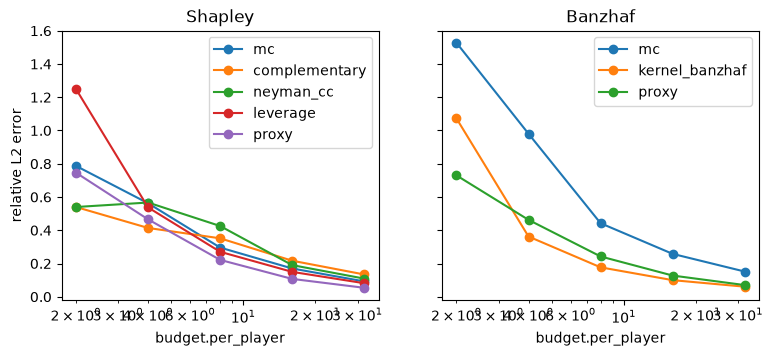

In [7]:
import matplotlib.pyplot as plt

figure, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for axis, rows, title in zip(axes, (shapley_rows, banzhaf_rows), ("Shapley", "Banzhaf")):
    for name in dict.fromkeys(name for name, _ in rows):
        axis.plot(ALPHAS, [rows[name, a][0] for a in ALPHAS], marker="o", label=name)
    axis.set(xscale="log", xlabel="budget.per_player", title=title)
    axis.legend()
axes[0].set_ylabel("relative L2 error")
plt.show()

## Reading the results

**Business:** the numbers above decide the estimator for your budget; the guide [Choosing an estimator](https://pawlo77.github.io/MLLM-SHAP/guides/choosing_an_estimator.html) summarises them.

**Technical:** the ranking depends on the game and the tables average five. `proxy` needs scikit-learn and fits trees on every aggregation, so reanalysis costs a fit.